# Lab Assignment 9: Natural Language Inference with Self-Attention

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_9.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

Natural Language Inference (NLI) is the task of determining whether a *hypothesis* sentence logically follows from a *premise* sentence. Given the premise "A dog is playing in the park" and the hypothesis "An animal is outdoors," a model should recognize **entailment**. Given the hypothesis "The dog is sleeping," it should recognize **contradiction**. Given "A cat is climbing a tree," it should recognize **neutral** — the premise neither guarantees nor rules out this claim.

NLI is a challenging test of natural language understanding because it requires the model to reason about the *relationship between two sequences* — not just classify a single text. Self-attention is particularly well suited to this: the attention mechanism can directly compare tokens across the premise and hypothesis, learning which token pairs are semantically compatible, contradictory, or unrelated.

In this lab you will implement a self-attention NLI classifier, apply it to the Stanford Natural Language Inference (SNLI) corpus, and systematically diagnose what the model has and has not learned — including a well-known failure mode where models exploit statistical biases in hypothesis text alone.

---

## Learning Objectives

1. Implement scaled dot-product self-attention from scratch and apply it to a real cross-sequence reasoning task
2. Analyze each component of the transformer architecture — multi-head attention, positional encoding, feed-forward sublayers, residual connections — and assess the role each plays in NLI performance
3. Compare transformer and RNN architectures on the NLI task, justifying when each is preferable
4. Evaluate the trained model by inspecting attention patterns and diagnosing the hypothesis-only bias failure mode

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Self-attention implementation and data preparation | 22 | Autograded (16) + Manual (6) |
| Part 2 — Transformer NLI classifier | 26 | Autograded (20) + Manual (6) |
| Part 3 — RNN baseline and architecture comparison | 20 | Autograded (14) + Manual (6) |
| Part 4 — Attention inspection and bias diagnosis | 18 | Autograded (12) + Manual (6) |
| Code quality | 14 | Manual |
| **Total** | **100** | Autograded (62) + Manual (38) |

### Manual grading rubric

**Reflections (6 pts each):**  
Full credit requires a specific, evidence-grounded claim connected to a concrete mechanism, using precise NLP terminology.

**Code quality (14 pts):**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 4 |
| Defensive coding | 3 |
| Code clarity and naming | 2 |
| Avoiding redundancy | 1 |

---

## Setup

**Runtime requirement:** GPU strongly recommended.  
In Google Colab: *Runtime → Change runtime type → T4 GPU.*

In [1]:
# Setup — run this cell first every session.

import subprocess, sys
from importlib import metadata

def install_if_missing(package, pip_name=None):
    """Install a package if it is missing or does not match a pinned version.

    The installed version is read from package metadata instead of by
    importing, so a pin such as "datasets==3.5.0" still replaces a newer
    preinstalled release (as on Colab) before the first import.

    Args:
        package  (str): Importable module name to check.
        pip_name (str): pip install name if different; may carry a
                        version pin, e.g. "datasets==3.5.0".

    Raises:
        subprocess.CalledProcessError: If the pip install fails.
    """
    spec = pip_name or package
    dist_name, _, pinned = spec.partition("==")
    try:
        installed = metadata.version(dist_name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed is None or (pinned and installed != pinned):
        subprocess.check_call([sys.executable, "-m", "pip",
                               "install", spec, "-q"])
        if package in sys.modules:
            print(f"{package} was already imported: restart the runtime "
                  "so the newly installed version is used.")

install_if_missing("torch")
install_if_missing("datasets", "datasets==3.5.0")
# Current datasets / huggingface_hub releases reject the namespace-less id
# "snli" used by load_dataset below, so pin a pair that still resolves it.
install_if_missing("huggingface_hub", "huggingface_hub==0.30.2")
install_if_missing("numpy")
install_if_missing("matplotlib")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt
import math, random, time
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
if DEVICE.type == 'cpu':
    print("No GPU detected. Colab: Runtime → Change runtime type → T4 GPU.")

# NLI label mapping (SNLI convention)
LABEL2ID = {'entailment': 0, 'neutral': 1, 'contradiction': 2}
ID2LABEL  = {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
N_CLASSES = 3

Device: cpu
No GPU detected. Colab: Runtime → Change runtime type → T4 GPU.


---

## Part 1 — Self-Attention Implementation and Data Preparation (22 points)

The module notebook had you implement self-attention on a short fixed-sequence toy example. Here you will implement the same mechanism, but now it needs to handle variable-length padded sequences with a padding mask — a practical requirement for batched NLI inputs.

You will also prepare the SNLI dataset by building a vocabulary, encoding premise-hypothesis pairs as a single concatenated sequence, and implementing the sinusoidal positional encoding that lets the model distinguish token positions.

### 1.1 — Scaled dot-product self-attention with masking

The module notebook implemented attention on a 4-token fixed-length sequence. For batched NLI inputs we need two extensions:
- **Batch dimension:** process multiple sequences simultaneously
- **Padding mask:** PAD tokens must not influence the attention scores of real tokens

The mask is an additive mask: positions to be ignored receive a score of $-\infty$ before softmax, driving their attention weight to zero.

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$

where $M_{ij} = -\infty$ if position $j$ is a PAD token, else $0$.

In [2]:
def scaled_dot_product_attention(Q, K, V, mask=None, dropout=None):
    """Compute scaled dot-product attention with optional additive mask.

    Handles both 2-D (single head: n × d_k) and 4-D
    (batch × heads × seq × d_k) inputs.

    Args:
        Q       (Tensor): Query matrix.  Shape (..., n_q, d_k).
        K       (Tensor): Key matrix.    Shape (..., n_k, d_k).
        V       (Tensor): Value matrix.  Shape (..., n_k, d_v).
        mask    (Tensor or None): Additive mask. Broadcast-compatible with
                                  (..., n_q, n_k). Use -1e9 for masked positions.
        dropout (callable or None): Applied to the attention weights before
                                  they weight V (e.g. an nn.Dropout). The
                                  returned alpha is taken before dropout.

    Returns:
        tuple:
            output (Tensor): Shape (..., n_q, d_v).
            alpha  (Tensor): Attention weights, shape (..., n_q, n_k).
                             Each row sums to 1.

    Raises:
        TypeError:  If Q, K or V is not a Tensor, or mask is boolean (it must
                    be an additive float mask).
        ValueError: If the feature or key dimensions do not line up, or the
                    mask does not broadcast to (..., n_q, n_k).
    """
    if not all(isinstance(t, torch.Tensor) for t in (Q, K, V)):
        raise TypeError("Q, K and V must be torch.Tensor")
    if (min(Q.dim(), K.dim(), V.dim()) < 2 or Q.size(-1) != K.size(-1)
            or K.size(-2) != V.size(-2)):
        raise ValueError(f"expected Q (..., n_q, d_k), K (..., n_k, d_k), V (..., n_k, d_v); "
                         f"got {tuple(Q.shape)}, {tuple(K.shape)}, {tuple(V.shape)}")

    # Dividing by sqrt(d_k) keeps the dot products near unit variance, so the
    # softmax does not saturate as d_k grows.
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.size(-1))     # (..., n_q, n_k)
    if mask is not None:
        if mask.dtype == torch.bool:
            raise TypeError("mask must be additive (0 keep, -1e9 drop), not boolean")
        try:
            fits = torch.broadcast_shapes(mask.shape, scores.shape) == scores.shape
        except RuntimeError:
            fits = False
        if not fits:
            raise ValueError(f"mask of shape {tuple(mask.shape)} does not broadcast "
                             f"to scores of shape {tuple(scores.shape)}")
        scores = scores + mask              # -1e9 on a masked key → weight ≈ 0 after softmax
    alpha = F.softmax(scores, dim=-1)       # normalise over keys: each row sums to 1
    weights = alpha if dropout is None else dropout(alpha)
    return weights @ V, alpha


# ── Verification ─────────────────────────────────────────────────────────────
torch.manual_seed(0)
n, d_k = 5, 8
Q_t = torch.randn(n, d_k)
K_t = torch.randn(n, d_k)
V_t = torch.randn(n, d_k)

out_t, alpha_t = scaled_dot_product_attention(Q_t, K_t, V_t)
print(f"Output shape: {out_t.shape}  (expected: [{n}, {d_k}])")
print(f"Alpha sums:   {alpha_t.sum(dim=-1).tolist()}  (all should be ≈ 1.0)")

# Mask test: position 4 is PAD — its column should be zeroed out
mask = torch.zeros(n, n)
mask[:, 4] = -1e9   # column 4 = PAD key
out_masked, alpha_masked = scaled_dot_product_attention(Q_t, K_t, V_t, mask)
print(f"\nMasked alpha column 4 (should be ≈ 0):  "
      f"{alpha_masked[:, 4].tolist()}")

# Compare to PyTorch reference (no mask)
ref = F.scaled_dot_product_attention(
    Q_t.unsqueeze(0), K_t.unsqueeze(0), V_t.unsqueeze(0)).squeeze(0)
print(f"Max diff vs PyTorch reference: {(out_t - ref).abs().max().item():.2e}"
      f"  (should be < 1e-5)")

Output shape: torch.Size([5, 8])  (expected: [5, 8])
Alpha sums:   [1.0, 1.0, 1.0000001192092896, 1.0, 1.0]  (all should be ≈ 1.0)



Masked alpha column 4 (should be ≈ 0):  [0.0, 0.0, 0.0, 0.0, 0.0]
Max diff vs PyTorch reference: 2.38e-07  (should be < 1e-5)


### 1.2 — Sinusoidal positional encoding

Self-attention is permutation-invariant without positional signals — the same attention weights would be produced regardless of token order. Positional encoding injects position information before the first attention layer.

Implement the sinusoidal encoding from Vaswani et al. (2017):

$$PE_{(pos, 2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right) \qquad PE_{(pos, 2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

In [3]:
def require_positive_ints(**named_values):
    """Raise ValueError unless every keyword argument is a positive int.

    Args:
        **named_values: name=value pairs to check, e.g. d_model=128.

    Raises:
        ValueError: If any value is not a positive int (bools are rejected).
    """
    for name, value in named_values.items():
        if isinstance(value, bool) or not isinstance(value, int) or value <= 0:
            raise ValueError(f"{name} must be a positive int, got {value!r}")


def sinusoidal_positional_encoding(seq_len, d_model, device='cpu'):
    """Generate sinusoidal positional encodings.

    Even columns 2i hold sin(pos / 10000^(2i/d)) and odd columns 2i+1 the
    matching cos, so an odd d_model has one more sin column than cos.

    Args:
        seq_len (int):        Number of positions.
        d_model (int):        Embedding dimension.
        device  (str):        Target device.

    Returns:
        Tensor: Shape (1, seq_len, d_model). Each position has a unique
                encoding; values lie in [-1, 1].

    Raises:
        ValueError: If seq_len or d_model is not a positive int.
    """
    require_positive_ints(seq_len=seq_len, d_model=d_model)
    positions = torch.arange(seq_len, dtype=torch.float32, device=device).unsqueeze(1)
    # 1 / 10000^(2i/d) for every even column 2i, computed as exp(-2i·ln(10000)/d).
    even_cols = torch.arange(0, d_model, 2, dtype=torch.float32, device=device)
    angles = positions * torch.exp(-math.log(10000.0) * even_cols / d_model)  # (seq_len, ceil(d/2))
    pe = torch.zeros(seq_len, d_model, device=device)
    pe[:, 0::2] = torch.sin(angles)
    pe[:, 1::2] = torch.cos(angles[:, :d_model // 2])    # floor(d/2) cos columns
    return pe.unsqueeze(0)


# Verify shape and properties
pe_check = sinusoidal_positional_encoding(10, 32)
print(f"PE shape: {pe_check.shape}  (expected: [1, 10, 32])")
print(f"Value range: [{pe_check.min().item():.3f}, {pe_check.max().item():.3f}]"
      f"  (should be in [-1, 1])")
# Adjacent positions must differ
diff = (pe_check[0, 1:] - pe_check[0, :-1]).abs().sum(dim=-1)
print(f"Adjacent position differences (all > 0): {(diff > 0).all().item()}")

PE shape: torch.Size([1, 10, 32])  (expected: [1, 10, 32])
Value range: [-0.990, 1.000]  (should be in [-1, 1])
Adjacent position differences (all > 0): True


### 1.3 — SNLI dataset and vocabulary

SNLI contains ~550k premise-hypothesis pairs with three labels. We use a 50k training subset for reasonable training time on a T4 GPU.

Each pair is encoded as a single sequence:  
`[CLS] premise tokens [SEP] hypothesis tokens [SEP]`  
This lets a single encoder see both sides and compute cross-sequence attention.

In [4]:
# [DO NOT MODIFY] — data loading

print("Loading SNLI...")
snli = load_dataset("snli")

# Filter out the small number of examples with label -1 (annotator disagreement)
def filter_labels(split):
    return [ex for ex in snli[split] if ex['label'] != -1]

train_raw = filter_labels('train')[:50_000]
val_raw   = filter_labels('validation')
test_raw  = filter_labels('test')

print(f"Train: {len(train_raw):,}  Val: {len(val_raw):,}  Test: {len(test_raw):,}")
print(f"\nSample:")
ex = train_raw[0]
print(f"  Premise:    {ex['premise']}")
print(f"  Hypothesis: {ex['hypothesis']}")
print(f"  Label:      {ID2LABEL[ex['label']]} ({ex['label']})")

Loading SNLI...


Train: 50,000  Val: 9,842  Test: 9,824

Sample:
  Premise:    A person on a horse jumps over a broken down airplane.
  Hypothesis: A person is training his horse for a competition.
  Label:      neutral (1)


In [5]:
# Special token indices
PAD_ID, CLS_ID, SEP_ID, UNK_ID = 0, 1, 2, 3
SPECIAL_TOKENS = ['<PAD>', '<CLS>', '<SEP>', '<UNK>']

def tokenize(text):
    """Lowercase a sentence and split it on whitespace.

    Shared by build_vocabulary and encode_pair so both see the same tokens.

    Args:
        text (str): Raw sentence.

    Returns:
        list[str]: Tokens.

    Raises:
        TypeError: If text is not a string.
    """
    if not isinstance(text, str):
        raise TypeError(f"text must be a str, got {type(text).__name__}")
    return text.lower().split()


def build_vocabulary(examples, min_freq=3):
    """Build word-to-index mapping from SNLI premise and hypothesis texts.

    Lowercases and splits on whitespace. Only includes words appearing
    at least min_freq times. Special tokens occupy indices 0-3. The other
    words follow in descending frequency, ties broken alphabetically, so
    the mapping is identical on every run.

    Args:
        examples  (list[dict]): SNLI examples with 'premise'/'hypothesis'.
        min_freq  (int):        Minimum token frequency to include.

    Returns:
        dict[str, int]: Word-to-index mapping.

    Raises:
        ValueError: If min_freq is not a positive int.
        TypeError:  If a premise or hypothesis is not a string.
    """
    require_positive_ints(min_freq=min_freq)
    counts = Counter()
    for ex in examples:
        counts.update(tokenize(ex['premise']))
        counts.update(tokenize(ex['hypothesis']))

    word2idx = {token: index for index, token in enumerate(SPECIAL_TOKENS)}  # PAD, CLS, SEP, UNK = 0-3
    for word, count in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0])):
        if count < min_freq:
            break                           # sorted by count, so no later word is more frequent
        word2idx[word] = len(word2idx)
    return word2idx


WORD2IDX = build_vocabulary(train_raw, min_freq=3)
IDX2WORD  = {i: w for w, i in WORD2IDX.items()}
VOCAB_SIZE = len(WORD2IDX)

print(f"Vocabulary size: {VOCAB_SIZE:,}")
print(f"Sample entries: {list(WORD2IDX.items())[4:12]}")

Vocabulary size: 11,532
Sample entries: [('a', 4), ('the', 5), ('in', 6), ('is', 7), ('man', 8), ('on', 9), ('and', 10), ('are', 11)]


In [6]:
MAX_LEN = 64   # max total sequence length (CLS + premise + SEP + hyp + SEP)

def encode_pair(premise, hypothesis, word2idx, max_len=MAX_LEN):
    """Encode a premise-hypothesis pair as a single padded token sequence.

    Format: [CLS] premise_tokens [SEP] hypothesis_tokens [SEP] [PAD...]

    Words missing from word2idx become UNK_ID. A pair longer than max_len is
    truncated longest-first (one token at a time from the end of whichever
    sentence is longer), so both SEP tokens always survive.

    Args:
        premise    (str):           Premise sentence.
        hypothesis (str):           Hypothesis sentence.
        word2idx   (dict[str,int]): Vocabulary mapping.
        max_len    (int):           Maximum sequence length (pad or truncate).

    Returns:
        tuple:
            ids  (list[int]): Token indices, length max_len.
            mask (list[int]): 1 for real tokens, 0 for PAD positions.

    Raises:
        ValueError: If max_len is not an int of at least 3 (CLS + two SEPs).
        TypeError:  If premise or hypothesis is not a string.
    """
    if isinstance(max_len, bool) or not isinstance(max_len, int) or max_len < 3:
        raise ValueError(f"max_len must be an int >= 3, got {max_len!r}")
    premise_ids = [word2idx.get(tok, UNK_ID) for tok in tokenize(premise)]
    hypothesis_ids = [word2idx.get(tok, UNK_ID) for tok in tokenize(hypothesis)]

    budget = max_len - 3                    # room left after CLS and the two SEPs
    while len(premise_ids) + len(hypothesis_ids) > budget:
        longer = premise_ids if len(premise_ids) >= len(hypothesis_ids) else hypothesis_ids
        longer.pop()

    ids = [CLS_ID] + premise_ids + [SEP_ID] + hypothesis_ids + [SEP_ID]
    n_pad = max_len - len(ids)
    return ids + [PAD_ID] * n_pad, [1] * len(ids) + [0] * n_pad


# Quick check
ids, mask = encode_pair("a dog runs", "an animal moves", WORD2IDX)
print(f"Token ids:  {ids[:12]}")
print(f"Attn mask:  {mask[:12]}")
print(f"Sequence starts with CLS ({CLS_ID}): {ids[0] == CLS_ID}")
print(f"SEP ({SEP_ID}) appears at positions: "
      f"{[i for i,v in enumerate(ids) if v == SEP_ID]}")

Token ids:  [1, 4, 29, 201, 2, 19, 439, 1160, 2, 0, 0, 0]
Attn mask:  [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0]
Sequence starts with CLS (1): True
SEP (2) appears at positions: [4, 8]


In [7]:
class SNLIDataset(Dataset):
    """PyTorch Dataset for SNLI premise-hypothesis pairs.

    Each item is (ids, mask, label): ids and mask are LongTensors of shape
    (max_len,) built by encode_pair, and label is a scalar LongTensor.

    Args:
        examples (list[dict]):     SNLI examples with 'premise', 'hypothesis'
                                   and 'label' keys.
        word2idx (dict[str, int]): Vocabulary mapping.
        max_len  (int):            Padded sequence length.
    """

    def __init__(self, examples, word2idx, max_len=MAX_LEN):
        self.data = []
        for ex in examples:
            ids, mask = encode_pair(ex['premise'], ex['hypothesis'],
                                     word2idx, max_len)
            self.data.append((
                torch.tensor(ids,  dtype=torch.long),
                torch.tensor(mask, dtype=torch.long),
                torch.tensor(ex['label'], dtype=torch.long)
            ))

    def __len__(self):
        """Number of premise-hypothesis pairs."""
        return len(self.data)

    def __getitem__(self, i):
        """Return pair i as (ids, mask, label) LongTensors."""
        return self.data[i]


BATCH_SIZE = 128

train_ds = SNLIDataset(train_raw, WORD2IDX)
val_ds   = SNLIDataset(val_raw,   WORD2IDX)
test_ds  = SNLIDataset(test_raw,  WORD2IDX)

train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   BATCH_SIZE)
test_loader  = DataLoader(test_ds,  BATCH_SIZE)

ids_b, mask_b, lbl_b = next(iter(train_loader))
print(f"Batch shapes — ids: {ids_b.shape}  mask: {mask_b.shape}  "
      f"labels: {lbl_b.shape}")
print(f"Label distribution in batch: "
      f"{ {ID2LABEL[k.item()]: v.item() for k, v in zip(*lbl_b.unique(return_counts=True))} }")

Batch shapes — ids: torch.Size([128, 64])  mask: torch.Size([128, 64])  labels: torch.Size([128])
Label distribution in batch: {'entailment': 38, 'neutral': 44, 'contradiction': 46}


### 1.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The padding mask ensures that PAD tokens do not influence the representations of real tokens. Explain what would happen to the attention scores — and the resulting token representations — if padding tokens were *not* masked. Why is this particularly harmful for NLI, where the same max-length padding is applied to both short and long premise-hypothesis pairs?

**Question B:** The CLS-SEP encoding concatenates premise and hypothesis into one sequence before the encoder. An alternative design would encode them separately with two encoders and then combine the representations. Identify one thing the CLS-SEP design can do that the separate-encoders design cannot, and explain the architectural reason.

**Your reflection:**

**A.** Without the additive mask, the softmax over $QK^\top/\sqrt{d_k}$ normalises over every key, PAD included, so PAD keys take probability mass from real tokens and each real token's output mixes in PAD value vectors. Part 5.1 shows this for the model trained with the mask and evaluated with `mask=None`: on the shortest validation pair, *Trucks racing* / *There are vehicles.*, the CLS query's last-layer, head-averaged weight on PAD keys rises from 0.0000 to 1.0000, and P(entailment) falls from 0.9302 to 0.4385 when padded to 32 tokens and to 0.4569 when padded to 64. The CLS vector thus depends on the PAD count, not only on the pair's content. This is particularly harmful in NLI because every pair is padded to 64: short pairs get far more PAD keys than long ones, so the attention diverted from the premise-hypothesis comparison varies with pair length, and validation accuracy falls from 0.5708 to 0.4825.

**B.** The CLS-SEP design lets each hypothesis token attend directly to each premise token, and vice versa, in every layer, because both segments form one sequence and share one score matrix $QK^\top$, as in BERT-style sentence-pair encoding (J&M, *Masked Language Models*). Separate encoders give each sentence its own attention matrix, so the sentences meet only after each is pooled into a fixed vector, whereas here hypothesis queries put 0.3949 of their last-layer attention on premise tokens (Part 5.2), a quantity that is zero by construction with two encoders.

---

## Part 2 — Transformer NLI Classifier (26 points)

### 2.1 — Multi-head self-attention

In [8]:
class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention using the scaled_dot_product_attention function.

    Projects input to Q, K, V for each head, runs attention in parallel,
    then concatenates and projects back to d_model.

    Args:
        d_model  (int): Model embedding dimension.
        n_heads  (int): Number of attention heads. Must divide d_model evenly.
        dropout  (float): Dropout on attention weights.

    Raises:
        ValueError:     If d_model or n_heads is not a positive int.
        AssertionError: If n_heads does not divide d_model.
    """

    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        require_positive_ints(d_model=d_model, n_heads=n_heads)
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k     = d_model // n_heads
        # One d_model × d_model projection per role; Q, K and V outputs are split into heads.
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def _split_heads(self, t):
        """Reshape projected inputs so each head is its own batch slice.

        Args:
            t (Tensor): Shape (batch, seq_len, d_model).

        Returns:
            Tensor: Shape (batch, n_heads, seq_len, d_k).
        """
        batch, seq_len, _ = t.shape
        return t.view(batch, seq_len, self.n_heads, self.d_k).transpose(1, 2)

    def forward(self, x, mask=None):
        """Forward pass.

        Args:
            x    (Tensor): Shape (batch, seq_len, d_model).
            mask (Tensor or None): Shape (batch, 1, 1, seq_len) or
                                   (batch, seq_len, seq_len) — additive mask.

        Returns:
            tuple:
                output   (Tensor): Shape (batch, seq_len, d_model).
                alpha    (Tensor): Attention weights averaged across heads,
                                   shape (batch, seq_len, seq_len).

        Raises:
            ValueError: If x is not (batch, seq_len, d_model) or the mask
                        does not broadcast to the attention scores.
        """
        if x.dim() != 3 or x.size(-1) != self.d_model:
            raise ValueError(f"x must have shape (batch, seq_len, {self.d_model}), "
                             f"got {tuple(x.shape)}")
        batch, seq_len, _ = x.shape
        if mask is not None and mask.dim() == 3:
            mask = mask.unsqueeze(1)        # (batch, seq, seq) → (batch, 1, seq, seq): shared by all heads

        Q, K, V = (self._split_heads(proj(x)) for proj in (self.W_q, self.W_k, self.W_v))
        heads, alpha = scaled_dot_product_attention(Q, K, V, mask, dropout=self.dropout)
        # Concatenate heads: (batch, n_heads, seq, d_k) → (batch, seq, d_model).
        concat = heads.transpose(1, 2).reshape(batch, seq_len, self.d_model)
        return self.W_o(concat), alpha.mean(dim=1)

### 2.2 — Transformer encoder layer

In [9]:
class TransformerEncoderLayer(nn.Module):
    """Single transformer encoder layer: MHA → Add&Norm → FFN → Add&Norm.

    Args:
        d_model  (int):   Embedding dimension.
        n_heads  (int):   Number of attention heads.
        d_ff     (int):   Feed-forward inner dimension (typically 4 × d_model).
        dropout  (float): Dropout probability.

    Raises:
        ValueError:     If d_model, n_heads or d_ff is not a positive int.
        AssertionError: If n_heads does not divide d_model.
    """

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        require_positive_ints(d_ff=d_ff)
        self.attn = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.ff1 = nn.Linear(d_model, d_ff)
        self.ff2 = nn.Linear(d_ff, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        """Forward pass with residual connections and layer norm.

        Args:
            x    (Tensor): Shape (batch, seq_len, d_model).
            mask (Tensor or None): Additive attention mask.

        Returns:
            tuple:
                output (Tensor): Shape (batch, seq_len, d_model).
                alpha  (Tensor): Mean attention weights, shape
                                 (batch, seq_len, seq_len).

        Raises:
            ValueError: If x is not (batch, seq_len, d_model) or the mask
                        does not broadcast to the attention scores.
        """
        attn_out, alpha = self.attn(x, mask)
        x = self.norm1(x + self.dropout(attn_out))              # Add & Norm (post-LN)
        ff_out = self.ff2(self.dropout(F.relu(self.ff1(x))))    # linear → ReLU → dropout → linear
        x = self.norm2(x + self.dropout(ff_out))                # Add & Norm
        return x, alpha

### 2.3 — NLI classifier

In [10]:
class TransformerNLI(nn.Module):
    """Transformer encoder for Natural Language Inference.

    Encodes [CLS] premise [SEP] hypothesis [SEP] as a single sequence,
    then classifies using the CLS token representation.

    Args:
        vocab_size (int):   Vocabulary size.
        d_model    (int):   Embedding dimension.
        n_heads    (int):   Attention heads.
        d_ff       (int):   Feed-forward inner dimension.
        n_layers   (int):   Number of stacked encoder layers.
        max_len    (int):   Maximum sequence length.
        n_classes  (int):   Number of NLI labels (3).
        dropout    (float): Dropout probability.

    Raises:
        ValueError:     If a size argument is not a positive int.
        AssertionError: If n_heads does not divide d_model.
    """

    def __init__(self, vocab_size, d_model=128, n_heads=4, d_ff=256,
                 n_layers=2, max_len=MAX_LEN, n_classes=3, dropout=0.1):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, n_layers=n_layers,
                              max_len=max_len, n_classes=n_classes)
        self.max_len = max_len
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        # A buffer moves with .to(device) and is saved with the model, but is not trained.
        self.register_buffer('pe', sinusoidal_positional_encoding(max_len, d_model))
        self.layers = nn.ModuleList([TransformerEncoderLayer(d_model, n_heads, d_ff, dropout)
                                     for _ in range(n_layers)])
        self.classifier = nn.Linear(d_model, n_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, ids, mask=None, return_attn=False):
        """Forward pass.

        Args:
            ids         (LongTensor):  Token ids, shape (batch, seq_len).
            mask        (LongTensor or None): Attention mask (1=real, 0=PAD),
                                              shape (batch, seq_len).
            return_attn (bool):        If True, return last-layer attention.

        Returns:
            tuple:
                logits (Tensor): Shape (batch, n_classes).
                alpha  (Tensor or None): Last-layer attention weights averaged
                                         over heads, shape (batch, seq_len,
                                         seq_len), if return_attn=True; else None.

        Raises:
            ValueError: If ids is not (batch, seq_len) with seq_len <= max_len,
                        or mask does not have the same shape as ids.
        """
        if ids.dim() != 2 or ids.size(1) > self.max_len:
            raise ValueError(f"ids must have shape (batch, seq_len <= {self.max_len}), "
                             f"got {tuple(ids.shape)}")
        if mask is not None and mask.shape != ids.shape:
            raise ValueError(f"mask shape {tuple(mask.shape)} must match ids {tuple(ids.shape)}")

        x = self.embedding(ids) + self.pe[:, :ids.size(1)]      # (batch, seq, d_model)
        attn_mask = None
        if mask is not None:
            # 1/0 mask → additive (batch, 1, 1, seq): -1e9 on PAD keys, shared by every head and query.
            attn_mask = (mask == 0).to(x.dtype)[:, None, None, :] * -1e9
        for layer in self.layers:
            x, alpha = layer(x, attn_mask)
        logits = self.classifier(self.dropout(x[:, 0]))         # CLS sits at position 0
        return logits, (alpha if return_attn else None)

### 2.4 — Training

In [11]:
def run_epoch(model, loader, optimizer=None, criterion=None, device=DEVICE, clip=None):
    """Run one training or evaluation epoch.

    If optimizer is None, runs in eval mode (no gradient updates).

    Args:
        model     (nn.Module):    NLI model returning (logits, alpha_or_None).
        loader    (DataLoader):   Yields (ids, mask, labels) batches.
        optimizer (torch.optim.Optimizer or None): If None, evaluation mode.
        criterion (nn.Module or None): Loss function; None uses
                                  nn.CrossEntropyLoss().
        device    (torch.device): Device the model is on.
        clip      (float or None): If set, clip the gradient norm to this
                                  value before each step; None (default)
                                  leaves gradients unclipped.

    Returns:
        tuple[float, float]: (average_loss, accuracy), both averaged per example.

    Raises:
        ValueError: If the loader yields no examples.
    """
    criterion = criterion if criterion is not None else nn.CrossEntropyLoss()
    training = optimizer is not None
    model.train(training)                   # dropout on only while training
    total_loss, n_correct, n_seen = 0.0, 0, 0
    with torch.set_grad_enabled(training):  # no autograd graph during evaluation
        for ids, mask, labels in loader:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            logits, _ = model(ids, mask)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                if clip is not None:
                    nn.utils.clip_grad_norm_(model.parameters(), clip)
                optimizer.step()
            # The criterion averages over the batch; weight by batch size so a
            # smaller final batch counts proportionally.
            total_loss += loss.item() * labels.size(0)
            n_correct += (logits.argmax(dim=1) == labels).sum().item()
            n_seen += labels.size(0)
    if n_seen == 0:
        raise ValueError("loader yielded no examples")
    return total_loss / n_seen, n_correct / n_seen


D_MODEL  = 128
N_HEADS  = 4
D_FF     = 256
N_LAYERS = 2
DROPOUT  = 0.1
N_EPOCHS = 5
LR       = 1e-3

transformer_model = TransformerNLI(
    vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_heads=N_HEADS,
    d_ff=D_FF, n_layers=N_LAYERS, max_len=MAX_LEN,
    n_classes=N_CLASSES, dropout=DROPOUT
).to(DEVICE)

optimizer = torch.optim.Adam(transformer_model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

print(f"Parameters: {sum(p.numel() for p in transformer_model.parameters()):,}")
print(f"Device: {DEVICE}\n")

tf_train_losses, tf_val_accs = [], []

for epoch in range(1, N_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(transformer_model, train_loader,
                                 optimizer, criterion)
    vl_loss, vl_acc = run_epoch(transformer_model, val_loader,
                                 criterion=criterion)
    tf_train_losses.append(tr_loss)
    tf_val_accs.append(vl_acc)
    print(f"Epoch {epoch}/{N_EPOCHS}  "
          f"train_loss={tr_loss:.4f}  train_acc={tr_acc:.3f}  "
          f"val_acc={vl_acc:.3f}  ({time.time()-t0:.0f}s)")

# Named output variable
transformer_val_acc = tf_val_accs[-1]
print(f"\nFinal validation accuracy: {transformer_val_acc:.4f}")

Parameters: 1,740,419
Device: cpu



Epoch 1/5  train_loss=1.0383  train_acc=0.460  val_acc=0.505  (40s)


Epoch 2/5  train_loss=0.9546  train_acc=0.541  val_acc=0.527  (37s)


Epoch 3/5  train_loss=0.9061  train_acc=0.577  val_acc=0.557  (34s)


Epoch 4/5  train_loss=0.8693  train_acc=0.604  val_acc=0.569  (33s)


Epoch 5/5  train_loss=0.8286  train_acc=0.629  val_acc=0.571  (33s)

Final validation accuracy: 0.5708


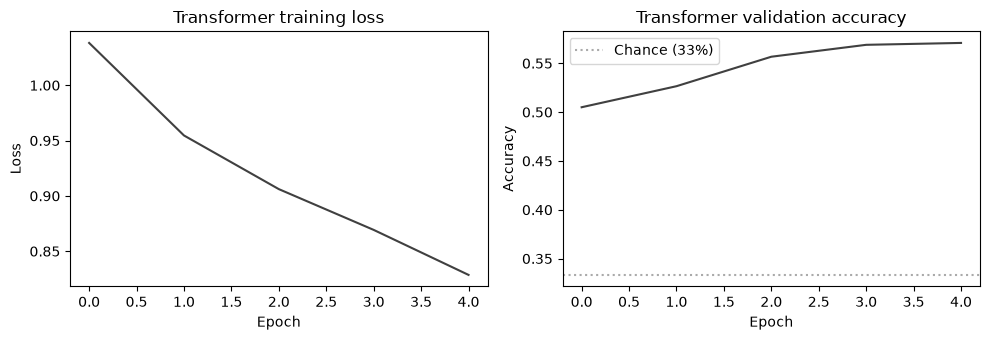

In [12]:
# [RUN] — training curve

fig_tf, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(tf_train_losses, color='#404040')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Transformer training loss')
axes[1].plot(tf_val_accs, color='#404040')
axes[1].axhline(1/3, color='#aaaaaa', linestyle=':', label='Chance (33%)')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Transformer validation accuracy')
axes[1].legend()
plt.tight_layout(); plt.show()

### 2.5 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The classifier uses only the CLS token representation to make its prediction. This means all information about the premise-hypothesis relationship must be aggregated into this one vector through the attention layers. Explain the mechanism by which the CLS token accumulates information from across the entire sequence — specifically, what role does self-attention play in this, and why is CLS-based classification a natural fit for this architecture?

**Question B:** This model uses 2 encoder layers and 4 attention heads. Describe what you would expect each of these design choices to trade off: what does adding more layers give you, and what does increasing the number of heads give you? For an NLI task with relatively short sequences (≤ 64 tokens), argue whether these hyperparameters seem appropriate or whether you would adjust them.

**Your reflection:**

**A.** CLS enters every input with the same embedding at position 0, so its output varies only with what its query retrieves: each layer scores $q_{\text{CLS}}^\top k_j/\sqrt{d_k}$ against every real key and averages their values by the softmax weights, so any token is one step away. Stacking matters because the last layer reads states that layer 1 has already mixed across the SEP: the final CLS query puts 0.8519 of its attention on hypothesis tokens (token share 0.3134) and only 0.1366 on the premise (Part 5.2), so premise evidence reaches it mostly indirectly, through those mixed states and its residual stream. CLS pooling fits an architecture with no final recurrent state: a fixed, content-free position becomes a learned pooling whose query is trained directly by the classification loss, as in BERT (J&M, *Masked Language Models*).

**B.** More layers compose attention, so later layers can relate states that already encode alignments, at the cost of parameters, overfitting and harder post-LN optimisation. More heads add distinct attention patterns at no parameter cost but cut each head's $d_k$, which bounds the rank of its scores (128/4 = 32 now, 16 with eight heads). For at most 64 tokens I would keep both, since one layer already links any two positions and two can align then aggregate; the logs point instead to more data and epochs, as training loss was still falling (0.8693 to 0.8286) and 11,532 × 128 = 1,476,096 of the 1,740,419 parameters are embeddings.

---

## Part 3 — RNN Baseline and Architecture Comparison (20 points)

### 3.1 — Bidirectional LSTM baseline

In [13]:
class LSTMNLIBaseline(nn.Module):
    """Bidirectional LSTM NLI classifier.

    Encodes the concatenated [premise; SEP; hypothesis] sequence with a
    BiLSTM, then classifies using the mean-pooled hidden states.

    Args:
        vocab_size (int):   Vocabulary size.
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   LSTM hidden units per direction.
        n_layers   (int):   Number of LSTM layers.
        n_classes  (int):   3 for NLI.
        dropout    (float): Dropout probability.

    Raises:
        ValueError: If a size argument is not a positive int.
    """

    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128,
                 n_layers=2, n_classes=3, dropout=0.1):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim, n_layers=n_layers, n_classes=n_classes)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        # nn.LSTM applies dropout only between layers, so a 1-layer LSTM gets none.
        self.lstm = nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True,
                            bidirectional=True, dropout=dropout if n_layers > 1 else 0.0)
        self.classifier = nn.Linear(hidden_dim * 2, n_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, ids, mask=None, return_attn=False):
        """Forward pass.

        Args:
            ids  (LongTensor): Shape (batch, seq_len).
            mask (LongTensor or None): 1=real token, 0=PAD (used for
                                       mean pooling over non-PAD positions).
                                       Real tokens must come first, as
                                       encode_pair produces. If None, it is
                                       derived from ids != PAD_ID.
            return_attn (bool): Ignored — LSTMs have no attention weights.
                                Returns None for the second value.

        Returns:
            tuple: (logits, None) — logits shape (batch, n_classes).

        Raises:
            ValueError: If ids is not 2-D or mask does not match ids.
        """
        if ids.dim() != 2:
            raise ValueError(f"ids must have shape (batch, seq_len), got {tuple(ids.shape)}")
        if mask is None:
            mask = (ids != PAD_ID).long()
        elif mask.shape != ids.shape:
            raise ValueError(f"mask shape {tuple(mask.shape)} must match ids {tuple(ids.shape)}")

        lengths = mask.sum(dim=1).clamp(min=1)  # >= 1: packing rejects 0 and the mean divides by it
        # Packing stops each direction at the last real token, so the backward
        # LSTM starts at the final SEP instead of reading the padding first.
        packed = nn.utils.rnn.pack_padded_sequence(self.embedding(ids), lengths.cpu(),
                                                   batch_first=True, enforce_sorted=False)
        packed_states, _ = self.lstm(packed)
        states, _ = nn.utils.rnn.pad_packed_sequence(packed_states, batch_first=True,
                                                     total_length=ids.size(1))  # zeros at PAD
        # Masked mean: PAD states are zero, so sum over positions / real length.
        pooled = states.sum(dim=1) / lengths.unsqueeze(1).to(states.dtype)
        return self.classifier(self.dropout(pooled)), None


lstm_model = LSTMNLIBaseline(
    vocab_size=VOCAB_SIZE, embed_dim=D_MODEL, hidden_dim=D_MODEL//2,
    n_layers=N_LAYERS, n_classes=N_CLASSES, dropout=DROPOUT
).to(DEVICE)

optimizer_lstm = torch.optim.Adam(lstm_model.parameters(), lr=LR)

print(f"LSTM parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")
print("Training LSTM baseline...")

lstm_train_losses, lstm_val_accs = [], []
for epoch in range(1, N_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(lstm_model, train_loader,
                                 optimizer_lstm, criterion)
    vl_loss, vl_acc = run_epoch(lstm_model, val_loader,
                                 criterion=criterion)
    lstm_train_losses.append(tr_loss)
    lstm_val_accs.append(vl_acc)
    print(f"Epoch {epoch}/{N_EPOCHS}  "
          f"train_loss={tr_loss:.4f}  train_acc={tr_acc:.3f}  "
          f"val_acc={vl_acc:.3f}  ({time.time()-t0:.0f}s)")

lstm_val_acc = lstm_val_accs[-1]
print(f"\nFinal validation accuracy: {lstm_val_acc:.4f}")

LSTM parameters: 1,675,139
Training LSTM baseline...


Epoch 1/5  train_loss=1.0112  train_acc=0.485  val_acc=0.537  (39s)


Epoch 2/5  train_loss=0.8886  train_acc=0.590  val_acc=0.603  (39s)


Epoch 3/5  train_loss=0.8123  train_acc=0.640  val_acc=0.617  (39s)


Epoch 4/5  train_loss=0.7522  train_acc=0.674  val_acc=0.623  (39s)


Epoch 5/5  train_loss=0.6942  train_acc=0.704  val_acc=0.627  (39s)

Final validation accuracy: 0.6267


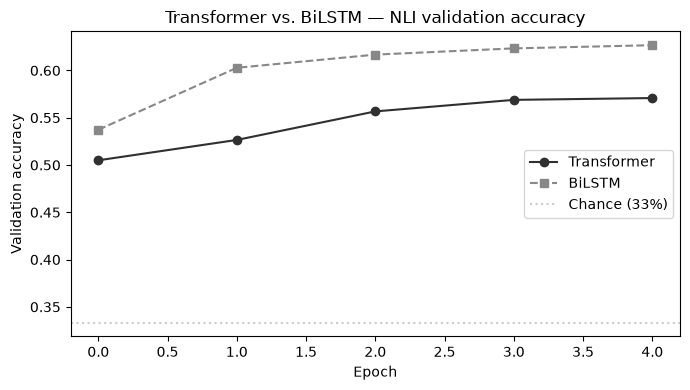

In [14]:
# [RUN] — comparison plot

fig_compare, ax = plt.subplots(figsize=(7, 4))
ax.plot(tf_val_accs,   '-o',  color='#303030', label='Transformer')
ax.plot(lstm_val_accs, '--s', color='#888888', label='BiLSTM')
ax.axhline(1/3, color='#cccccc', linestyle=':', label='Chance (33%)')
ax.set(xlabel='Epoch', ylabel='Validation accuracy',
       title='Transformer vs. BiLSTM — NLI validation accuracy')
ax.legend(); plt.tight_layout(); plt.show()

### 3.2 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** NLI requires comparing two sequences — the model must detect when a hypothesis is *entailed by*, *contradicted by*, or *unrelated to* the premise. Explain why self-attention is architecturally better suited to this comparison than an LSTM. Focus on the specific operation that allows the transformer to directly relate a token in the hypothesis to a token in the premise, and contrast it with how the LSTM must accomplish the same thing.

**Question B:** The module reading notes that transformers are preferred when training data is abundant and sequences are short-to-medium length, while RNNs may be preferable with limited data and longer sequences. Given that SNLI has 550k examples but we trained on only 50k, and sequences are truncated to 64 tokens, does the observed accuracy gap between the two models match the expected pattern? Justify your answer.

**Your reflection:**

**A.** Self-attention relates a hypothesis token $i$ to a premise token $j$ in one operation, the scaled dot product $q_i^\top k_j/\sqrt{d_k}$ followed by a softmax over all keys, so every cross-sentence pair is scored directly and in parallel, one layer apart whatever the distance. In this model hypothesis queries put 0.3949 of their last-layer attention on premise tokens (Part 5.2). The BiLSTM computes no pairwise score: one sentence reaches the other only through the fixed-size recurrent state, rewritten by the gates at every intervening step, so the comparison is learned implicitly before mean pooling (J&M, *RNNs and LSTMs*).

**B.** Yes, it matches the limited-data side of the pattern: short sequences favour the transformer, but 50k of SNLI's roughly 550k pairs is limited data, and the BiLSTM leads at every epoch, finishing at 0.6267 against 0.5708, a gap of 0.6267 − 0.5708 = 0.0559 at comparable size (1,675,139 versus 1,740,419 parameters). The likely mechanism is inductive bias: recurrence builds in word order and locality, while the transformer must learn to use fixed sinusoidal encodings for order and learn its attention patterns from scratch, which takes more data. Part 5.4 supports this, since an uninformative premise costs the BiLSTM 0.0441 accuracy but the transformer only 0.0062, so at 50k pairs the transformer has not learned to make its cross-sentence attention improve accuracy; whether the full data, or a tuned learning-rate schedule, would reverse the ranking is something this run cannot test.

---

## Part 4 — Attention Inspection and Bias Diagnosis (18 points)

### 4.1 — Attention entropy

A focused attention head concentrates weight on a few positions (low entropy). A diffuse head spreads weight uniformly (high entropy). Entropy quantifies this:

$$H(\alpha_i) = -\sum_j \alpha_{ij} \log \alpha_{ij}$$

A head with entropy close to $\log(n)$ (maximum) attends uniformly and has likely not specialised.

In [15]:
def attention_entropy(alpha, eps=1e-12):
    """Compute per-position attention entropy.

    H[i] = -sum_j alpha[i, j] * log(alpha[i, j] + eps), in nats, taken over
    the last (key) dimension: a row spread evenly over n keys scores log(n),
    a one-hot row scores 0. Leading dimensions (e.g. batch, heads) are kept.

    Args:
        alpha (Tensor or np.ndarray): Attention weights, shape (..., seq_len),
                        typically (seq_len, seq_len). Each row along the last
                        dimension is a probability distribution.
        eps   (float):  Keeps the log finite where a weight is exactly 0.

    Returns:
        Tensor: Entropy per query position, shape (...); (seq_len,) for a
                (seq_len, seq_len) input.

    Raises:
        TypeError:  If alpha is neither a Tensor nor an np.ndarray.
        ValueError: If alpha is 0-dimensional.
    """
    if not isinstance(alpha, (torch.Tensor, np.ndarray)):
        raise TypeError(f"alpha must be a Tensor or np.ndarray, got {type(alpha).__name__}")
    alpha = torch.as_tensor(alpha)
    if alpha.dim() < 1:
        raise ValueError("alpha must have shape (..., seq_len), got a scalar")
    return -(alpha * torch.log(alpha + eps)).sum(dim=-1)


def encode_pair_tensors(premise, hypothesis, word2idx, device=DEVICE, max_len=MAX_LEN):
    """Encode one premise-hypothesis pair as a batch of one.

    Args:
        premise    (str):            Premise sentence.
        hypothesis (str):            Hypothesis sentence.
        word2idx   (dict[str, int]): Vocabulary mapping.
        device     (torch.device):   Device for the returned tensors.
        max_len    (int):            Padded sequence length.

    Returns:
        tuple[LongTensor, LongTensor]: (ids, mask), each shape (1, max_len).

    Raises:
        ValueError: If max_len is not an int of at least 3 (from encode_pair).
        TypeError:  If premise or hypothesis is not a string (from encode_pair).
    """
    ids, mask = encode_pair(premise, hypothesis, word2idx, max_len)
    return (torch.tensor([ids], dtype=torch.long, device=device),
            torch.tensor([mask], dtype=torch.long, device=device))


@torch.no_grad()
def forward_single_pair(model, ids, mask, device=DEVICE):
    """Eval-mode forward pass on one encoded pair, without gradients.

    Leaves the model in eval mode.

    Args:
        model  (nn.Module):          TransformerNLI or LSTMNLIBaseline.
        ids    (LongTensor):         Shape (1, seq_len).
        mask   (LongTensor or None): Shape (1, seq_len); None runs the model
                                     without a padding mask.
        device (torch.device):       Device the model is on.

    Returns:
        tuple:
            probs (np.ndarray):         Class probabilities, shape (n_classes,).
            alpha (np.ndarray or None): Last-layer attention averaged over
                                        heads, shape (seq_len, seq_len); None
                                        for a model without attention.

    Raises:
        TypeError:  If ids is not a Tensor.
        ValueError: If ids is not (1, seq_len) or mask does not match it.
    """
    if not isinstance(ids, torch.Tensor):
        raise TypeError(f"ids must be a LongTensor, got {type(ids).__name__}")
    if ids.dim() != 2 or ids.size(0) != 1:
        raise ValueError(f"ids must have shape (1, seq_len), got {tuple(ids.shape)}")
    if mask is not None and mask.shape != ids.shape:
        raise ValueError(f"mask shape {tuple(mask.shape)} must match ids {tuple(ids.shape)}")
    model.eval()                            # dropout off
    logits, alpha = model(ids.to(device), None if mask is None else mask.to(device),
                          return_attn=True)
    probs = F.softmax(logits[0], dim=-1).cpu().numpy()
    return probs, (None if alpha is None else alpha[0].cpu().numpy())


def get_attention_weights(model, ids, mask, device=DEVICE):
    """Run a forward pass and return last-layer attention weights.

    Args:
        model  (TransformerNLI):  Trained model.
        ids    (LongTensor):       Shape (1, seq_len).
        mask   (LongTensor):       Shape (1, seq_len).
        device (torch.device):     Device the model is on.

    Returns:
        np.ndarray: Attention weights, shape (seq_len, seq_len).
                    Averaged across heads, last encoder layer only.

    Raises:
        TypeError:  If ids is not a Tensor.
        ValueError: If ids or mask has the wrong shape, or the model returns
                    no attention weights (e.g. the BiLSTM).
    """
    _, alpha = forward_single_pair(model, ids, mask, device)
    if alpha is None:
        raise ValueError("model returned no attention weights; pass a TransformerNLI")
    return alpha

### 4.2 — Attention heatmap visualization

  Premise:    A man is playing guitar on a stage.
  Hypothesis: A musician is performing.
  Predicted:  entailment



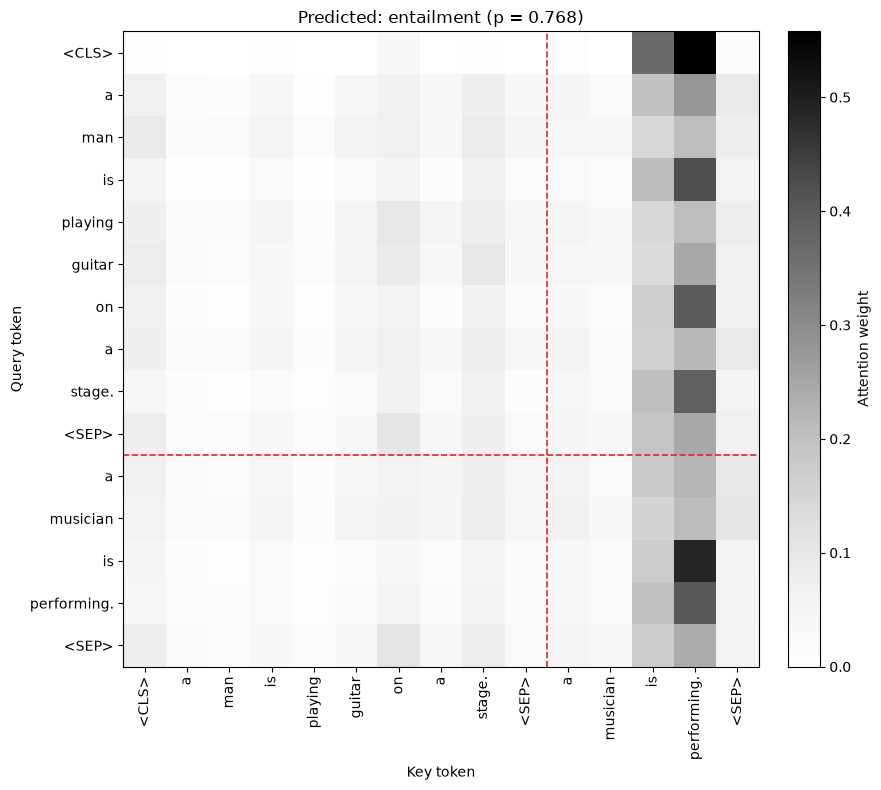

  Premise:    A woman is reading a book.
  Hypothesis: No one is reading anything.
  Predicted:  contradiction



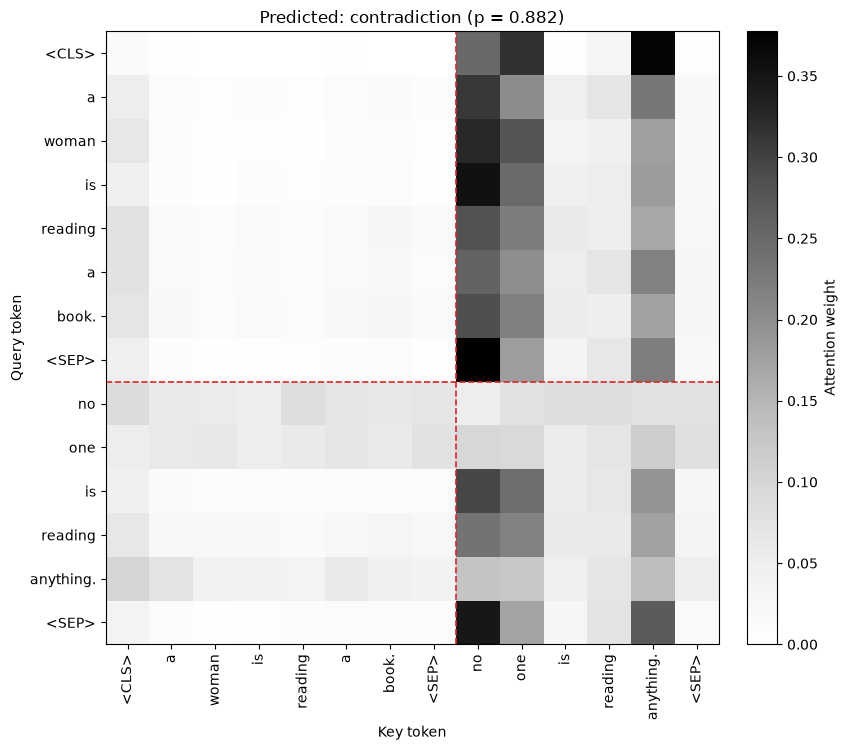

  Premise:    Children are playing in a park.
  Hypothesis: People are outside.
  Predicted:  entailment



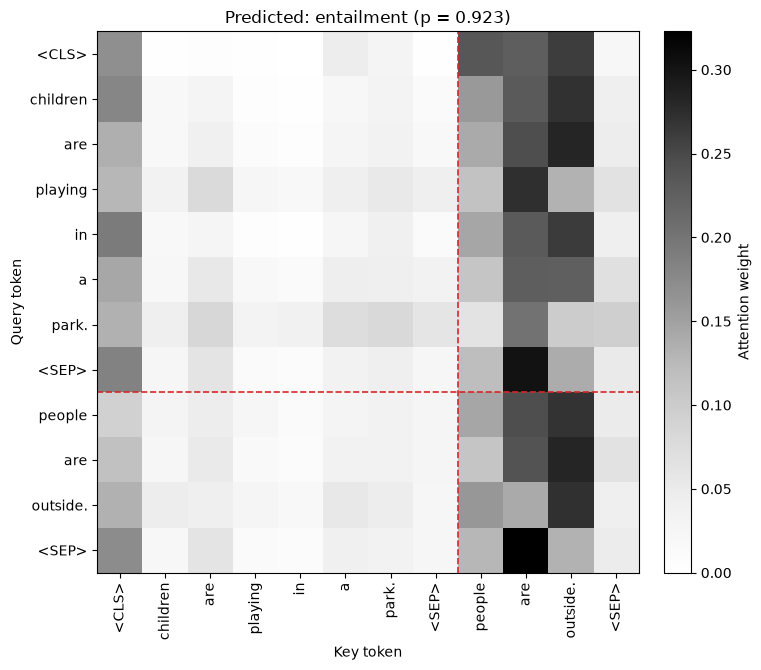

In [16]:
def plot_nli_attention(premise, hypothesis, model, word2idx, device=DEVICE):
    """Plot attention heatmap for a premise-hypothesis pair.

    Displays token labels on axes, with the SEP boundary marked.
    Row = query token, column = key token. PAD rows and columns are
    trimmed, and the figure is left open for the caller to show.

    Args:
        premise    (str):              Premise sentence.
        hypothesis (str):              Hypothesis sentence.
        model      (TransformerNLI):   Trained model.
        word2idx   (dict[str, int]):   Vocabulary mapping.
        device     (torch.device):     Device the model is on.

    Returns:
        tuple: (fig, ax, prediction_label)

    Raises:
        TypeError:  If premise or hypothesis is not a string.
        ValueError: If the model returns no attention weights (e.g. the BiLSTM).
    """
    ids, mask = encode_pair_tensors(premise, hypothesis, word2idx, device,
                                    max_len=getattr(model, 'max_len', MAX_LEN))
    probs, alpha = forward_single_pair(model, ids, mask, device)   # one pass gives both
    if alpha is None:
        raise ValueError("model returned no attention weights; pass a TransformerNLI")
    pred_id = int(probs.argmax())
    n_real = int(mask.sum())
    alpha = alpha[:n_real, :n_real]             # drop PAD rows and columns

    token_ids = ids[0, :n_real].tolist()
    idx2word = {index: word for word, index in word2idx.items()}
    tokens = [idx2word.get(index, SPECIAL_TOKENS[UNK_ID]) for index in token_ids]
    boundary = token_ids.index(SEP_ID) + 0.5   # between the premise's SEP and the hypothesis

    size = 2 + 0.4 * n_real
    fig, ax = plt.subplots(figsize=(size + 1, size))
    image = ax.imshow(alpha, cmap='Greys', vmin=0)
    ax.set_xticks(range(n_real))
    ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticks(range(n_real))
    ax.set_yticklabels(tokens)
    ax.axvline(boundary, color='#d62728', linestyle='--', linewidth=1.2)
    ax.axhline(boundary, color='#d62728', linestyle='--', linewidth=1.2)
    ax.set(xlabel='Key token', ylabel='Query token',
           title=f"Predicted: {ID2LABEL[pred_id]} (p = {probs[pred_id]:.3f})")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label='Attention weight')
    fig.tight_layout()
    return fig, ax, ID2LABEL[pred_id]


# Visualise three representative examples:
# (1) entailment, (2) contradiction, (3) neutral
examples_to_plot = [
    ("A man is playing guitar on a stage.",
     "A musician is performing."),
    ("A woman is reading a book.",
     "No one is reading anything."),
    ("Children are playing in a park.",
     "People are outside.")
]

for premise, hypothesis in examples_to_plot:
    fig_attn, _, pred = plot_nli_attention(
        premise, hypothesis, transformer_model, WORD2IDX)
    print(f"  Premise:    {premise}")
    print(f"  Hypothesis: {hypothesis}")
    print(f"  Predicted:  {pred}\n")
    plt.show()

### 4.3 — Hypothesis-only bias diagnosis

Gururangan et al. (2018) showed that NLI models can exploit **hypothesis-only biases**: statistical patterns in hypothesis text that correlate with labels regardless of the premise. For example, hypotheses with negation words ("no", "never", "not") are more likely to be labeled *contradiction*; hypotheses with superlatives ("the most", "only") tend toward *entailment*; generic statements ("a person is doing something") tend toward *neutral*.

A model that has learned these biases will score well on regular examples but fail on diagnostic minimal contrast pairs where the bias signal is absent or reversed.

In [17]:
def predict_nli(model, premise, hypothesis, word2idx, device=DEVICE):
    """Predict NLI label and return class probabilities.

    Args:
        model      (nn.Module):       Trained model.
        premise    (str):             Premise sentence.
        hypothesis (str):             Hypothesis sentence.
        word2idx   (dict[str, int]):  Vocabulary mapping.
        device     (torch.device):    Device the model is on.

    Returns:
        tuple:
            pred_label  (str):         Predicted label string.
            probs       (np.ndarray):  Class probabilities, shape (3,);
                                       index = label id (0 entailment,
                                       1 neutral, 2 contradiction).

    Raises:
        TypeError: If premise or hypothesis is not a string.
    """
    # Models without a max_len attribute (the BiLSTM) take the default length.
    ids, mask = encode_pair_tensors(premise, hypothesis, word2idx, device,
                                    max_len=getattr(model, 'max_len', MAX_LEN))
    probs, _ = forward_single_pair(model, ids, mask, device)
    return ID2LABEL[int(probs.argmax())], probs


# ── Test 1: Hypothesis-only bias probes ──────────────────────────────────────
# For each probe, the premise is deliberately uninformative.
# A model that learned the task should be UNCERTAIN (near 33% each class).
# A biased model will confidently predict the biased label.

UNINFORMATIVE_PREMISE = "Some people are doing things."

bias_probes = [
    # (hypothesis,                       expected_bias,      biased_label)
    ("There is no one present.",          "negation",         "contradiction"),
    ("Nobody moved at all.",              "negation",         "contradiction"),
    ("A person is doing something.",      "vague generic",    "neutral"),
    ("Someone is doing some activity.",   "vague generic",    "neutral"),
    ("The only person is working.",       "superlative",      "entailment"),
    ("A man is the best athlete.",        "superlative",      "entailment"),
]

print(f"{'Hypothesis':<40s} {'Predicted':>14s} {'P(contra)':>10s} "
      f"{'P(neutral)':>10s} {'P(entail)':>10s}")
print("-" * 88)
for hyp, bias_type, expected_bias in bias_probes:
    pred, probs = predict_nli(transformer_model, UNINFORMATIVE_PREMISE,
                               hyp, WORD2IDX)
    marker = " ← BIASED" if pred == expected_bias else ""
    print(f"{hyp:<40s} {pred:>14s} {probs[2]:>10.3f} "
          f"{probs[1]:>10.3f} {probs[0]:>10.3f}{marker}")

Hypothesis                                    Predicted  P(contra) P(neutral)  P(entail)
----------------------------------------------------------------------------------------
There is no one present.                  contradiction      0.877      0.037      0.087 ← BIASED
Nobody moved at all.                      contradiction      0.979      0.009      0.012 ← BIASED
A person is doing something.                 entailment      0.013      0.043      0.944
Someone is doing some activity.              entailment      0.056      0.090      0.854
The only person is working.               contradiction      0.930      0.033      0.037
A man is the best athlete.                      neutral      0.192      0.550      0.258


In [18]:
# ── Test 2: Minimal contrast pairs ───────────────────────────────────────────
# Each pair differs in exactly one word. The label should flip.
# Correct behavior: both predictions correct.
# Bias failure: the model ignores the contrast and predicts the same label.

CONTRAST_PAIRS = [
    # (premise,                        hyp_A,                   label_A,
    #                                  hyp_B,                   label_B)
    ("A dog is running in the field.",
     "An animal is moving.",           "entailment",
     "No animal is moving.",           "contradiction"),

    ("A woman is cooking dinner.",
     "Someone is preparing food.",     "entailment",
     "No one is preparing food.",      "contradiction"),

    ("Two men are playing chess.",
     "People are playing a game.",     "entailment",
     "People are not playing a game.", "contradiction"),

    ("A child is sleeping in a bed.",
     "A person is resting.",           "entailment",
     "A person is wide awake.",        "contradiction"),

    ("A group of people are dancing.",
     "Some people are moving.",        "entailment",
     "Nobody is moving.",              "contradiction"),
]

n_correct = 0
print(f"{'Premise':<35s} {'Hyp A':>30s} {'PredA':>13s} "
      f"{'Hyp B':>30s} {'PredB':>13s} {'Both✓':>6s}")
print("-" * 132)

for premise, hyp_a, lbl_a, hyp_b, lbl_b in CONTRAST_PAIRS:
    pred_a, _ = predict_nli(transformer_model, premise, hyp_a, WORD2IDX)
    pred_b, _ = predict_nli(transformer_model, premise, hyp_b, WORD2IDX)
    both_right = (pred_a == lbl_a and pred_b == lbl_b)
    n_correct += int(both_right)
    tick = "✓" if both_right else "✗"
    print(f"{premise[:33]:<35s} {hyp_a[:28]:>30s} {pred_a:>13s} "
          f"{hyp_b[:28]:>30s} {pred_b:>13s} {tick:>6s}")

# Named output variable
contrast_pair_accuracy = n_correct / len(CONTRAST_PAIRS)
print(f"\nContrast pair accuracy: {n_correct}/{len(CONTRAST_PAIRS)} "
      f"= {contrast_pair_accuracy:.2%}")

Premise                                                      Hyp A         PredA                          Hyp B         PredB  Both✓
------------------------------------------------------------------------------------------------------------------------------------
A dog is running in the field.                An animal is moving.    entailment           No animal is moving. contradiction      ✓
A woman is cooking dinner.              Someone is preparing food.    entailment      No one is preparing food.    entailment      ✗
Two men are playing chess.              People are playing a game.    entailment   People are not playing a gam contradiction      ✓
A child is sleeping in a bed.                 A person is resting.    entailment        A person is wide awake.    entailment      ✗
A group of people are dancing.             Some people are moving.    entailment              Nobody is moving. contradiction      ✓

Contrast pair accuracy: 3/5 = 60.00%


### 4.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Look at the attention heatmaps for the three example pairs. Identify one specific cell or region where the attention is *not* on the diagonal (not attending to the same-position token) and explain what cross-sequence relationship the model might be capturing at that point. Then identify one heatmap where attention is unexpectedly diffuse and propose a reason why.

**Question B:** The hypothesis-only bias probes test whether the model is using the premise at all. Based on your results, does the model show evidence of hypothesis-only bias? Connect your answer to the module reading's warning about attention weights not being reliable explanations: even if the heatmaps show the model "attending to" the premise, what would the bias probes reveal if that attention were not actually driving predictions?

**Your reflection:**

**A.** In heatmap 1 the premise query *stage.*[8] puts 0.3875 on the hypothesis key *performing.*[13] (Part 5.3), plausibly the inference that playing on a stage entails *performing*, though *is*[3] (0.4222) and *on*[6] (0.3979) weight it more, so it is a key-driven column, not a word alignment. In heatmap 2 the row of *no*[8], on which the contradiction turns, is unexpectedly diffuse: entropy 2.6257 nats against the uniform maximum log(14) = 2.6391. The negation likely works as a key, read by premise rows (*is*[3] → *no*[8] 0.3540), while its own query has little to retrieve, and the head average can flatten the row further.

**B.** Yes: replacing every premise with *Some people are doing things.* lowers accuracy only from 0.5708 to 0.5646 (Part 5.4) against a majority-class rate of 0.3382, and both negation probes go to contradiction (P(contradiction) 0.877 and 0.979). The generic and superlative probes miss their biased labels, plausibly because that premise is not neutral to them (*A person is doing something.* nearly paraphrases it; *The only person* clashes with *Some people*), and *A person is wide awake.*, the only contrast-pair contradiction without a negation word, is called entailment because only the premise reveals the clash. This makes the module reading's warning concrete (Jain & Wallace, 2019): real premises draw 0.3949 of hypothesis-query attention (Part 5.2), yet swapping their content barely changes accuracy, so that attention contributes little to correct predictions, and without such a test it explains nothing (Wiegreffe & Pinter, 2019; J&M, *Interpretability*).

---

## Part 5 — Supporting checks (ungraded)

These cells run after every graded cell and only read the graded variables and trained models, so no graded value changes. They print the exact numbers the reflections quote. Helper names start with `sc_` (supporting check) so they cannot collide with any graded name.

### 5.1 — The padding mask at work (Part 1 A)

The shortest validation pair goes through the trained transformer with its padding mask and with `mask=None`, padded to 32 and to 64 tokens. `CLS->PAD` is the last-layer attention weight (averaged over heads) that the CLS query puts on PAD keys. The last two lines give full validation accuracy with and without the mask.

In [19]:
def sc_predict_loader(model, loader, use_mask=True, device=DEVICE):
    """Predicted and gold labels for every example in a loader (eval mode, no gradients).

    Args:
        model    (nn.Module):    Trained NLI model returning (logits, alpha).
        loader   (DataLoader):   Yields (ids, mask, labels) batches.
        use_mask (bool):         If False, the model gets mask=None.
        device   (torch.device): Device the model is on.

    Returns:
        tuple[np.ndarray, np.ndarray]: (predictions, gold labels), each shape (n,).
    """
    model.eval()
    preds, golds = [], []
    with torch.no_grad():
        for ids, mask, labels in loader:
            logits, _ = model(ids.to(device), mask.to(device) if use_mask else None)
            preds.append(logits.argmax(dim=1).cpu())
            golds.append(labels)
    return torch.cat(preds).numpy(), torch.cat(golds).numpy()


def sc_report_padding_mask(model):
    """Print CLS attention on PAD keys, padding-length sensitivity and accuracy, mask on vs off.

    Args:
        model (TransformerNLI): Trained transformer.
    """
    ex = min(val_raw, key=lambda e: len(tokenize(e['premise'])) + len(tokenize(e['hypothesis'])))
    print(f"Pair: {ex['premise']!r} / {ex['hypothesis']!r}  (gold: {ID2LABEL[ex['label']]})\n")
    print(f"{'Mask':<5s} {'Padded to':>9s} {'CLS->PAD':>9s}"
          + "".join(f"{'P(' + ID2LABEL[c] + ')':>17s}" for c in range(N_CLASSES)))
    for use_mask in (True, False):
        probs_by_len = []
        for max_len in (32, MAX_LEN):
            ids, mask = encode_pair_tensors(ex['premise'], ex['hypothesis'], WORD2IDX, max_len=max_len)
            probs, alpha = forward_single_pair(model, ids, mask if use_mask else None)
            probs_by_len.append(probs)
            pad_mass = alpha[0, mask[0].cpu().numpy() == 0].sum()      # CLS row, PAD columns
            print(f"{'on' if use_mask else 'off':<5s} {max_len:>9d} {pad_mass:>9.4f}"
                  + "".join(f"{p:>17.4f}" for p in probs))
        print(f"      max |P(32) - P(64)| = {np.abs(probs_by_len[0] - probs_by_len[1]).max():.2e}")
    print()
    for use_mask in (True, False):
        preds, labels = sc_predict_loader(model, val_loader, use_mask)
        print(f"Validation accuracy, mask {'on ' if use_mask else 'off'}: {(preds == labels).mean():.4f}")


sc_report_padding_mask(transformer_model)

Pair: 'Trucks racing' / 'There are vehicles.'  (gold: entailment)

Mask  Padded to  CLS->PAD    P(entailment)       P(neutral) P(contradiction)


on           32    0.0000           0.9302           0.0495           0.0203
on           64    0.0000           0.9302           0.0495           0.0203
      max |P(32) - P(64)| = 0.00e+00
off          32    1.0000           0.4385           0.2317           0.3297
off          64    1.0000           0.4569           0.2567           0.2864
      max |P(32) - P(64)| = 4.33e-02



Validation accuracy, mask on : 0.5708


Validation accuracy, mask off: 0.4825


### 5.2 — Where CLS and the hypothesis tokens attend (Part 1 B, Part 2 A, Part 3 A, Part 4 B)

Mean last-layer attention (averaged over heads) on each key segment, over the full validation set. *CLS* is the classifier's query row; *Hypothesis queries* averages each pair's hypothesis-token rows, then averages over pairs. *Token share* is the fraction of each pair's real tokens in that segment, which is what a uniform row would give. *Special* means CLS and the two SEPs.

In [20]:
def sc_segment_masks(ids):
    """Boolean masks for the premise, hypothesis, special (CLS/SEP) and PAD positions.

    Args:
        ids (LongTensor): Encoded pairs, shape (batch, seq_len).

    Returns:
        dict[str, BoolTensor]: Segment name -> mask of shape (batch, seq_len).
    """
    special = (ids == CLS_ID) | (ids == SEP_ID)
    seps_so_far = (ids == SEP_ID).cumsum(dim=1)     # 0 in the premise, 1 in the hypothesis
    return {'premise': (seps_so_far == 0) & ~special, 'hypothesis': (seps_so_far == 1) & ~special,
            'special': special, 'pad': ids == PAD_ID}


def sc_report_attention_by_segment(model, loader, device=DEVICE):
    """Print the mean last-layer attention CLS and hypothesis queries put on each segment.

    Args:
        model  (TransformerNLI): Trained transformer.
        loader (DataLoader):     Yields (ids, mask, labels) batches.
        device (torch.device):   Device the model is on.
    """
    rows = ('CLS', 'Hypothesis queries', 'Token share')
    sums = {row: Counter() for row in rows}
    model.eval()
    with torch.no_grad():
        for ids, mask, _ in loader:
            ids, mask = ids.to(device), mask.to(device)
            _, alpha = model(ids, mask, return_attn=True)                # (batch, seq, seq)
            segments = sc_segment_masks(ids)
            hyp_rows = segments['hypothesis'].float()
            for name, keys in segments.items():
                keys = keys.float()
                mass = (alpha * keys[:, None, :]).sum(dim=-1)            # each query's weight on these keys
                sums['CLS'][name] += mass[:, 0].sum().item()
                sums['Hypothesis queries'][name] += (
                    (mass * hyp_rows).sum(1) / hyp_rows.sum(1).clamp(min=1)).sum().item()
                sums['Token share'][name] += ((keys * mask).sum(1) / mask.sum(1)).sum().item()
    n_pairs = len(loader.dataset)
    print(f"Validation pairs: {n_pairs:,}\n\n{'Query':<20s}" + "".join(f"{name:>12s}" for name in sums['CLS']))
    for row in rows:
        print(f"{row:<20s}" + "".join(f"{total / n_pairs:>12.4f}" for total in sums[row].values()))


sc_report_attention_by_segment(transformer_model, val_loader)

Validation pairs: 9,842

Query                    premise  hypothesis     special         pad
CLS                       0.1366      0.8519      0.0115      0.0000
Hypothesis queries        0.3949      0.5102      0.0949      0.0000
Token share               0.5530      0.3134      0.1336      0.0000


### 5.3 — The three heatmaps in numbers (Part 4 A)

For each pair in `examples_to_plot`: the mean row entropy of the trimmed heatmap against log(*n*), its maximum for *n* real tokens; the most diffuse query row; and the three strongest cells that link a premise word to a hypothesis word, in either direction (these are never on the diagonal). `token[i]` is the token at position *i*.

In [21]:
def sc_report_heatmaps(model, top_k=3):
    """Print entropy and the strongest premise-hypothesis cells of each examples_to_plot heatmap.

    Args:
        model (TransformerNLI): Trained transformer.
        top_k (int):            Number of cross-segment cells to list per pair.
    """
    for premise, hypothesis in examples_to_plot:
        ids, mask = encode_pair_tensors(premise, hypothesis, WORD2IDX, max_len=model.max_len)
        n_real = int(mask.sum())
        probs, alpha = forward_single_pair(model, ids, mask)
        alpha = alpha[:n_real, :n_real]                                   # real tokens, as in the heatmap
        entropy = attention_entropy(alpha).numpy()
        tokens = [f"{IDX2WORD[i]}[{pos}]" for pos, i in enumerate(ids[0, :n_real].tolist())]
        seg = {name: m[0].cpu().numpy() for name, m in sc_segment_masks(ids[:, :n_real]).items()}
        cross = np.outer(seg['premise'], seg['hypothesis']) | np.outer(seg['hypothesis'], seg['premise'])
        top_cells = np.argsort(np.where(cross, alpha, -1.0), axis=None)[::-1][:top_k]
        diffuse = int(entropy.argmax())
        print(f"{premise} / {hypothesis}  ->  {ID2LABEL[int(probs.argmax())]} (p = {probs.max():.4f})")
        print(f"  mean row entropy {entropy.mean():.4f} nats   log(n) = {math.log(n_real):.4f}   (n = {n_real})")
        print(f"  most diffuse query: {tokens[diffuse]}   H = {entropy[diffuse]:.4f}")
        for query, key in zip(*np.unravel_index(top_cells, alpha.shape)):
            print(f"  {tokens[query]:>16s} -> {tokens[key]:<16s} {alpha[query, key]:.4f}")
        print()


sc_report_heatmaps(transformer_model)

A man is playing guitar on a stage. / A musician is performing.  ->  entailment (p = 0.7678)
  mean row entropy 2.1723 nats   log(n) = 2.7081   (n = 15)
  most diffuse query: man[2]   H = 2.4823
             is[3] -> performing.[13]  0.4222
             on[6] -> performing.[13]  0.3979
         stage.[8] -> performing.[13]  0.3875

A woman is reading a book. / No one is reading anything.  ->  contradiction (p = 0.8817)
  mean row entropy 2.0385 nats   log(n) = 2.6391   (n = 14)
  most diffuse query: no[8]   H = 2.6257
             is[3] -> no[8]            0.3540
          woman[2] -> no[8]            0.3260
              a[1] -> no[8]            0.3095

Children are playing in a park. / People are outside.  ->  entailment (p = 0.9233)
  mean row entropy 2.0372 nats   log(n) = 2.4849   (n = 12)
  most diffuse query: park.[6]   H = 2.3519
            are[2] -> outside.[10]     0.2825
        playing[3] -> are[9]           0.2725
       children[1] -> outside.[10]     0.2700



### 5.4 — How much each model relies on the hypothesis alone (Part 3 B, Part 4 B)

Validation accuracy of both models with the real premise and with every premise replaced by `UNINFORMATIVE_PREMISE`, then accuracy within each gold class (recall) under both conditions. A model that ignored the premise would score the same in both columns; one with no hypothesis-only signal would fall to the majority-class rate once the premise is gone. Parameter counts and per-epoch times are in the two training cells' outputs.

In [22]:
def sc_report_hypothesis_only(models):
    """Print accuracy and per-class recall with real and with uninformative premises.

    Args:
        models (dict[str, nn.Module]): Display name -> trained model.
    """
    no_premise = SNLIDataset([{**ex, 'premise': UNINFORMATIVE_PREMISE} for ex in val_raw], WORD2IDX)
    conditions = {'real': val_loader, 'uninformative': DataLoader(no_premise, BATCH_SIZE)}
    results = {(name, cond): sc_predict_loader(model, loader)
               for name, model in models.items() for cond, loader in conditions.items()}
    gold = next(iter(results.values()))[1]
    print(f"Validation pairs: {len(gold):,}   majority-class accuracy: "
          f"{np.bincount(gold).max() / len(gold):.4f}\n")
    print(f"{'Model':<12s} {'Real premise':>13s} {'Uninformative':>14s} {'Drop':>8s}")
    for name in models:
        real, blank = (np.mean(np.equal(*results[name, cond])) for cond in conditions)
        print(f"{name:<12s} {real:>13.4f} {blank:>14.4f} {real - blank:>8.4f}")
    print(f"\nPer-class accuracy (recall):\n{'':<20s}" + "".join(f"{name:>29s}" for name in models))
    print(f"{'Gold class':<14s} {'n':>5s}" + f"{'real':>13s}{'uninformative':>16s}" * len(models))
    for c in range(N_CLASSES):
        in_class = gold == c
        recalls = [(preds[in_class] == c).mean() for preds, _ in results.values()]  # model-major order
        print(f"{ID2LABEL[c]:<14s} {in_class.sum():>5d}"
              + "".join(f"{r:>{w}.4f}" for r, w in zip(recalls, [13, 16] * len(models))))


sc_report_hypothesis_only({'Transformer': transformer_model, 'BiLSTM': lstm_model})

Validation pairs: 9,842   majority-class accuracy: 0.3382

Model         Real premise  Uninformative     Drop
Transformer         0.5708         0.5646   0.0062
BiLSTM              0.6267         0.5826   0.0441

Per-class accuracy (recall):
                                      Transformer                       BiLSTM
Gold class         n         real   uninformative         real   uninformative
entailment      3329       0.5257          0.6558       0.6675          0.3839
neutral         3235       0.6343          0.5790       0.6219          0.6739
contradiction   3278       0.5540          0.4579       0.5900          0.6943


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All four reflections filled in
- [x] Named output variables defined:  
  `transformer_val_acc`, `lstm_val_acc`, `contrast_pair_accuracy`
- [x] All three attention heatmaps rendered
- [x] Every function has a complete docstring
- [x] File saved as `Lab_9.ipynb`